### 사람과 탈것 객체를 검출하는 모델로 학습시키기

In [1]:
import torch
print('GPU 사용 가능여부:', torch.cuda.is_available())

GPU 사용 가능여부: True


In [2]:
#욜로 모델 불러오기
from ultralytics import YOLO
model= YOLO('yolo26n.pt')

In [3]:
#모델 훈련시키기
model.train(
    data='yolo-person-vehicle-dataset/data.yaml',
    epochs=10,
    imgsz=640,
    batch=32, #기본 16
    device=0
)

Ultralytics 8.4.208  Python-3.14.9 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo-person-vehicle-dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000020D60C7A030>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([0.        , 0.001001  , 0.002002  , 0.003003  , 0.004004  ,
       0.00500501, 0.00600601, 0.00700701, 0.00800801, 0.00900901,
       0.01001001, 0.01101101, 0.01201201, 0.01301301, 0.01401401,
       0.01501502, 0.01601602, 0.01701702, 0.01801802, 0.01901902,
       0.02002002, 0.02102102, 0.02202202, 0.02302302, 0.02402402,
       0.02502503, 0.02602603, 0.02702703, 0.02802803, 0.02902903,
       0.03003003, 0.03103103, 0.03203203, 0.03303303, 0.03403403,
       0.03503504, 0.03603604, 0.03703704, 0.03803804, 0.03903904,
       0.04004004, 0.04104104, 0.04204204, 0.04304304, 0.04404404,
       0.04504505, 0.04604605, 0.04704705, 0.048

In [15]:
#학습이 완료되면 runs폴더 생김
#runs/detect/train/ 폴더안에 최고의 성능이 측정된 best 가중치 값이 존재함
#이 best.pt 로 새로운 YOLO 모델 만들기

model= YOLO('runs/detect/train/weights/best.pt')
#results= model('test-image/person_vehicle.jpg') #.predict()없이 사용가능. 자동 forward()
results= model('test-image/person_vehicle2.webp')
results[0].show()


image 1/1 c:\Users\YOLO\MBCA\04 Computer Vision\03 YOLO Custom\test-image\person_vehicle2.webp: 448x640 3 persons, 2 vehicles, 36.2ms
Speed: 3.4ms preprocess, 36.2ms inference, 5.2ms postprocess per image at shape (1, 3, 448, 640)


In [6]:
#시각화된 이미지를 저장
for i, result in enumerate(results):
    save_path= f"output/detected_image_{i}.jpg"
    result.save(filename=save_path)

In [7]:
#results 에서 바운딩 박스 정보 추출
for result in results:
    for box in result.boxes:
        xyxy= box.xyxy[0].tolist() #박스 좌표
        class_name= result.names[ int(box.cls[0]) ] #클래스 명
        conf= box.conf[0].item() #신뢰도 점수

        print(f"object:{class_name}, score:{conf:.2f}, bbox:{xyxy}")

object:vehicle, score:0.90, bbox:[378.51715087890625, 241.12168884277344, 662.8363647460938, 384.1695251464844]
object:person, score:0.86, bbox:[260.760986328125, 184.25375366210938, 385.4133605957031, 494.1517028808594]


In [ ]:
# 바운딩 박스 영역의 이미지를 잘라서 파일로 저장하기
from PIL import Image
import numpy as np

# 결과로 받은 텐서이미지를 자르기 위해 픽셀배열로 만들기
origin_img= results[0].orig_img
origin_img_pillow= Image.fromarray(origin_img)

for i, result in enumerate(results):
    for n, box in enumerate(result.boxes):
        x1,y1, x2,y2= map(int, box.xyxy[0].tolist())
        #이미지 자르기
        cropped_image= origin_img_pillow.crop((x1,y1,x2,y2))
        #잘린 이미지를 파일로 저장
        cropped_image.save(f'output/detected_object_{n}.jpg')

#색상이 이상할 것임. origin image는 BGR로 되어 있음.

In [10]:
results[0].orig_img

array([[[244, 239, 236],
        [237, 234, 230],
        [200, 198, 197],
        ...,
        [185, 194, 208],
        [183, 192, 206],
        [181, 190, 204]],

       [[220, 225, 223],
        [226, 231, 229],
        [220, 225, 224],
        ...,
        [185, 194, 208],
        [183, 192, 206],
        [181, 190, 204]],

       [[237, 240, 244],
        [212, 215, 219],
        [182, 182, 188],
        ...,
        [185, 194, 208],
        [183, 192, 206],
        [182, 191, 205]],

       ...,

       [[ 88,  83,  82],
        [ 91,  86,  85],
        [ 77,  72,  73],
        ...,
        [ 72,  62,  55],
        [ 69,  59,  52],
        [ 57,  47,  40]],

       [[ 90,  85,  82],
        [ 93,  88,  87],
        [ 77,  72,  71],
        ...,
        [ 68,  58,  51],
        [ 67,  57,  50],
        [ 58,  48,  41]],

       [[ 93,  88,  85],
        [ 96,  91,  88],
        [ 77,  72,  71],
        ...,
        [ 61,  51,  44],
        [ 64,  54,  47],
        [ 60,  50,  43]]

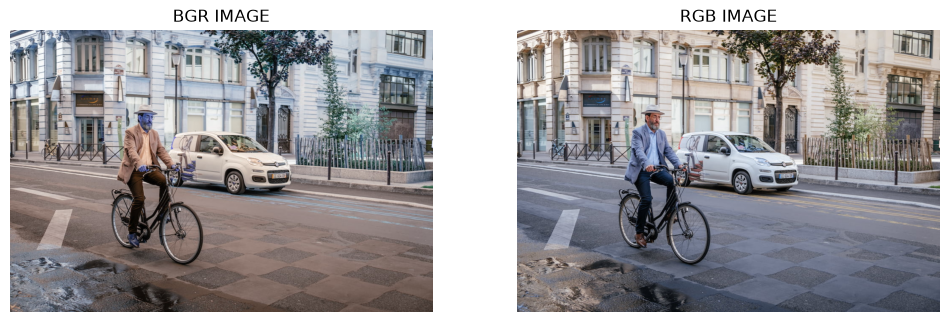

In [11]:
#BGR원본이미지 --> RGB로 변환 후 비교
import cv2
import matplotlib.pyplot as plt

bgr_image= origin_img
rgb_image= cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12,6))

plt.subplot(1,2, 1)
plt.imshow(bgr_image)
plt.title('BGR IMAGE')
plt.axis('off')

plt.subplot(1,2, 2)
plt.imshow(rgb_image)
plt.title('RGB IMAGE')
plt.axis('off')

plt.show()

In [14]:
# 바운딩 박스 영역의 이미지를 잘라서 파일로 저장하기

# 결과로 받은 텐서이미지를 자르기 위해 픽셀배열로 만들기
origin_img_pillow= Image.fromarray(rgb_image)

for i, result in enumerate(results):
    for n, box in enumerate(result.boxes):
        x1,y1, x2,y2= map(int, box.xyxy[0].tolist())
        #이미지 자르기
        cropped_image= origin_img_pillow.crop((x1,y1,x2,y2))
        #잘린 이미지를 파일로 저장
        cropped_image.save(f'output/detected_object_{n}.jpg')

#색상이 이상할 것임. origin image는 BGR로 되어 있음.